In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import dataclasses
import pickle
import os

Mounted at /content/drive


In [ ]:
import sys, os

GIT_USER  = "JoeyTurn"
GIT_REPO  = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git
!git clone https://github.com/dkarkada/expt-core.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)


Cloning into 'kernel_ICL'...
remote: Enumerating objects: 798, done.
remote: Counting objects: 100% (333/333), done.
remote: Compressing objects: 100% (232/232), done.
remote: Total 798 (delta 198), reused 231 (delta 96), pack-reused 465 (from 1)
Receiving objects: 100% (798/798), 55.73 MiB | 20.09 MiB/s, done.
Resolving deltas: 100% (392/392), done.
Cloning into 'expt-core'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (41/41), done.
Receiving objects: 100% (58/58), 16.11 KiB | 8.05 MiB/s, done.
remote: Total 58 (delta 28), reused 47 (delta 17), pack-reused 0 (from 0)
Resolving deltas: 100% (28/28), done.


In [ ]:
sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)

In [ ]:
%matplotlib inline
import math
import os

import numpy as np
import torch
import matplotlib.pyplot as plt

from kernels_can_icl.kernel_theory_multidim import generate_multidim_kicl_monomials
from kernels_can_icl.kernel_eigsys import eigendecompose, kernel_matrix
from kernels_can_icl.task_distrs import RegressionTaskDistribution
from kernels_can_icl.level_coefficients import *
from kernels_can_icl.utils import estimate_max_n, seed_everything, ensure_torch, ensure_numpy

In [ ]:
config = {
    "seed": 42,
    "dim": 4,
    "L": 7,
    "distribution": "pretrain",
    "T": 1,
    "sigma_sq": 0.1,
    "draw_betas": "normal",
    "beta_sd": 1.0,
    "trials": 1,
    "kernel_class": "PolynomialKernel",
    "kernel_params": {
        "ridge": 0.01,#1,
        "kernel_width": 3,
        "max_degree": 3,
        # "coeffs": [1.0, 0.111, 0.00617283951, 0.000228623685], #Gaussian
        # "coeffs": [1.1635035, 0.6293589, 0.1348020/2, 0.0173722/6], #ReLUTNK
        # "coeffs": [4.412876e-01, 5.993699e-02, (1.809221e-02)/2, (1.011731e-02)/6] #LAP, L=10
        "coeffs": [1.0, 0.111, 0.00617283951, 0.000228623685]
    },
    "n": 25600,
    "min_n": 2,
    "max_n": 30000,
    "memory_safety": 0.2,
    "matrix_factor": 3.0,
    "max_retries": 10,
    "retry_shrink": 0.96,
    "expt_dir": "kernel_ICL/validation",
    "base_name": "HEA_validation_T1_innerprod",
}

In [ ]:
def pref_point_closed(betas, v, vq, e, L, d, w2):
    t = 1.0 / (2*w2)
    N2 = (betas**2).sum(1)                      # ‖β_τ‖², shape (T,)
    g  = 1 + 2*t*e + 2*t*v*N2/(1 + 2*t*v)
    return ((1+2*t*vq)**(-d/2) * (1+2*t*v)**(-d*(L-1)/2)
            * ensure_numpy(torch.mean(g**(-(L-1)/2))))

    """
HEA diagnostics for the Laplace kernel K(x,x') = exp(-||x-x'||/sigma).

Given a data matrix, reports:
  r        reference radius, sqrt(Tr[Sigma])
  beta     sqrt(2) * r / sigma
  g_hat    gamma_1 / Tr[Sigma]   (top PCA mode's share of the variance)
  d_eff    Tr[Sigma]^2 / Tr[Sigma^2]
  c_ell    corrected on-sphere level coefficients
  rho_ell  gamma_1 * c_{ell+1} / c_ell   (the Gram-Schmidt control parameter)

Note the sigma convention: the paper uses exp(-||x-x'||/sigma); the authors'
repo uses exp(-||x-x'||/(sqrt(2)*sigma)). Pass paper_convention=False if your
sigma came from their code.
"""

import numpy as np
from math import factorial


def reverse_bessel(n, b):
    """Reverse Bessel polynomial theta_n(b); theta_{-1} = 1."""
    if n < 0:
        return 1.0
    return sum(
        factorial(n + k) / (factorial(n - k) * factorial(k)) * b ** (n - k) / 2 ** k
        for k in range(n + 1)
    )


def laplace_level_coeffs(r, beta, ell_max=6):
    """c_ell = e^{-beta} / r^{2 ell} * (beta / 2^ell) * theta_{ell-1}(beta)."""
    e = np.exp(-beta)
    c = [e]
    for l in range(1, ell_max + 1):
        c.append(e / r ** (2 * l) * (beta / 2 ** l) * reverse_bessel(l - 1, beta))
    return np.array(c)


def hea_report(X, sigma, center=True, ell_max=6, paper_convention=True):
    X = np.asarray(X, dtype=np.float64).reshape(len(X), -1)
    if center:
        X = X - X.mean(axis=0, keepdims=True)

    N = len(X)
    # covariance spectrum without forming Sigma (cheap when d is large)
    sv = np.linalg.svd(X, compute_uv=False)
    gamma = sv ** 2 / N

    tr = gamma.sum()
    r = np.sqrt(tr)
    g_hat = gamma[0] / tr
    d_eff = tr ** 2 / (gamma ** 2).sum()

    beta = np.sqrt(2) * r / sigma
    if not paper_convention:          # repo's exp(-||dx||/(sqrt(2) sigma))
        beta = r / sigma

    c = laplace_level_coeffs(r, beta, ell_max)
    rho = gamma[0] * c[1:] / c[:-1]
    ell_min = 1.0 / g_hat             # level where HEA eigenvalues start diverging

    print(f"N = {N}, d = {X.shape[1]}")
    print(f"r      = {r:.6f}      (Tr[Sigma] = {tr:.6f})")
    print(f"sigma  = {sigma:.6f}")
    print(f"beta   = {beta:.6f}")
    print(f"gamma1 = {gamma[0]:.6f}")
    print(f"g_hat  = {g_hat:.4f}       (want <= ~0.05)")
    print(f"d_eff  = {d_eff:.1f}        (want >= ~20 for Laplace)")
    print(f"ell_min ~ r^2/gamma1 = {ell_min:.1f}   (truncate well below this)")
    print("\n ell        c_ell        rho_ell = gamma1*c_{l+1}/c_l")
    for l in range(ell_max):
        print(f"  {l}    {c[l]:14.6e}    {rho[l]:8.3f}")
    print(f"  {ell_max}  {c[ell_max]:14.6e}")

    ok = [l for l in range(ell_max) if rho[l] < 0.3]
    top = max(ok) + 1 if ok else 0
    print(f"\nLevels with rho < 0.3: trustworthy up to ell = {top}")
    if d_eff < 20:
        print("WARNING: d_eff below 20 - norms will not concentrate enough "
              "for the on-sphere dot-product approximation.")
    if ell_min < 10:
        print("WARNING: divergence sets in early; keep the truncation order small.")

    return dict(r=r, beta=beta, gamma=gamma, g_hat=g_hat, d_eff=d_eff,
                c=c, rho=rho, ell_min=ell_min)

In [ ]:
@staticmethod
def get_level_coeff_fn(rho=1):
    w_var, b_var = 1,1

    rho = rho
    q = b_var + w_var * rho
    c0 = b_var / q
    if abs(c0) >= 1.0:
        raise ValueError("|c0|=1 makes higher derivatives singular; ensure w_var>0.")

    pref = w_var * q / (2*np.pi)
    scale = w_var / q

    def _poly_add(a, b, sa=1.0, sb=1.0):
        n = max(len(a), len(b))
        out = [0.0]*n
        for i in range(n):
            va = a[i] if i < len(a) else 0.0
            vb = b[i] if i < len(b) else 0.0
            out[i] = sa*va + sb*vb
        return out

    def _poly_eval(cs, c):
        p = 0.0
        for k in reversed(range(len(cs))):
            p = p*c + cs[k]
        return p

    def eval_level_coeff(ell):
        P = [3.0, 0.0, -2.0]
        if ell == 0:
            c = float(np.clip(c0, -1.0, 1.0))
            Gk_at_c0 = np.sqrt(max(0.0, 1.0 - c**2)) + 2.0*(np.pi - np.arccos(c))*c
        elif ell == 1:
            c = float(np.clip(c0, -1.0, 1.0))
            denom = np.sqrt(max(0.0, 1.0 - c**2))
            Gk_at_c0 = 2.0*(np.pi - np.arccos(c)) + (c/denom if denom > 0 else float('inf'))
        elif ell == 2:
            Gk_at_c0 = _poly_eval(P, c0) / (1.0 - c0*c0)**1.5
        else:
            for cur_ell in range(2, ell):
                term1 = [k*P[k] for k in range(1, len(P))]
                term1 = _poly_add(term1, [0.0, 0.0] + term1, 1.0, -1.0)
                term2 = [0.0] + list(P)
                P = _poly_add(term1, term2, 1.0, (2*cur_ell - 1))
            Gk_at_c0 = _poly_eval(P, c0) / (1.0 - c0*c0)**(ell - 0.5)
        return pref * (scale**ell) * float(Gk_at_c0)

    return eval_level_coeff

In [ ]:
def generate_data(task_distr: RegressionTaskDistribution, batch_sz):
    X_ctx, y_ctx, X_q, y_q = task_distr.generate_data(
        context_len=int(config["L"]), batch_sz=int(batch_sz),
        distribution=str(config["distribution"]), uniform_beta_sampling=True,
    )
    X = task_distr._get_input(X_ctx, y_ctx, X_q)
    y = y_q.squeeze(-1).squeeze(-1)
    return X, y


def run_once(n: int):
    task_distr = RegressionTaskDistribution(
        dim=int(config["dim"]), num_weights=int(config["T"]),
        noise_variance=float(config["sigma_sq"]), sample_beta=str(config["draw_betas"]),
        sigma_beta2=float(config["beta_sd"]) ** 2, gram_wanted=False,
        context_len=int(config["L"]),
    )
    context_length = int(config["L"])
    dim = int(config["dim"])
    X_flat, y_vec = generate_data(task_distr, batch_sz=n)

    X_flat = ensure_torch(X_flat)
    data_eigvals = (
        [task_distr.sigma_x2] * (context_length - 1) * dim
        + [dim * task_distr.sigma_x2 * task_distr.sigma_beta2+float(config["sigma_sq"])] * (context_length - 1)
        + [task_distr.sigma_q2] * dim
    )
    rho = np.array(data_eigvals).sum()
    print(rho)
    X_flatter = X_flat - X_flat.mean(axis=0, keepdims=True)     # center: paper assumes E[x] = 0
    X_flatter = ensure_numpy(X_flatter)
    # hea_report(X_flatter, sigma=3.0)

    w2 = config["kernel_params"]["kernel_width"] ** 2        # 9
    z = (X_flat ** 2).sum(dim=1) / (2 * w2)                  # ‖x‖²/2w², shape (N,)
    pref_point  = torch.exp(-z).mean().item()                # E[exp(−‖x‖²/2w²)]
    # pref_kernel = pref_point ** 2
    print(pref_point**2)

    y_vec = ensure_torch(y_vec)

    pref_kernel = pref_point_closed(betas=task_distr.pretrain_W.detach(), v=task_distr.sigma_x2,
                                vq=task_distr.sigma_q2,e=float(config["sigma_sq"]), L=(context_length - 1), d=dim,
                                    w2=w2)**2          # scale on th_eigvals
    print(pref_kernel)

    K = kernel_matrix(X_flat, config["kernel_class"], dict(config["kernel_params"]))
    emp_eigvals, emp_eigvecs = eigendecompose(K)
    print(f"Empiricial eigendecom done")
    # emp_eigcoeffs = emp_eigvecs.T @ y_vec
    # y_norm_sq = torch.dot(y_vec, y_vec).clamp_min(1e-12)
    # emp_eigcoeffs_sq_normalized = emp_eigcoeffs ** (2.) / y_norm_sq
    level_coeffs = get_polynomial_coefficients(config["kernel_params"]["coeffs"])
    print(f"Generating eigvals")
    th_eigvals, monomials, _impt_list, _degree_mass = generate_multidim_kicl_monomials(
        data_eigvals, num_monomials=int(1.2 * n), eval_level_coeff=level_coeffs,
        context_length=context_length, dim=dim, betas=task_distr.pretrain_W.detach(),
        noise_var=float(config["sigma_sq"]), kmax=8,
    )

    # th_eigvecs = ensure_torch(compute_hermite_basis(
    #     X_flat, monomials, context_length=context_length, dim=dim,
    #     betas=task_distr.pretrain_W.detach(), is_X_PCAd=True,
    # ))
    # th_eigcoeffs_sq_normalized = (th_eigvecs.T @ y_vec) ** (2.) / y_norm_sq

    return {
        "emp_eigvals": emp_eigvals,
        "emp_eigvecs": emp_eigvecs,
        "pp": pref_kernel,
        # "emp_eigcoeffs_sq_normalized": emp_eigcoeffs_sq_normalized,
        # "gaussian_beta_weight_fractions": gaussian_beta_weight_fractions(
        #     beta_samples=task_distr.pretrain_W.detach(),
        #     distr=str(config["distribution"]).lower(),
        # ),
        "th_eigvals": th_eigvals,
        # "th_eigvecs": th_eigvecs,
        # "th_eigcoeffs_sq_normalized": th_eigcoeffs_sq_normalized,
        "monomials": monomials,
    }

In [ ]:
# gen, rng = seed_everything(config["seed"], device_id=0)

n = estimate_max_n(config=config, n=config.get("n"))
retries = int(config["max_retries"])
shrink = float(config["retry_shrink"])
last_err = None

for _attempt in range(retries + 1):
    try:
        out = run_once(n=n)
        break
    except RuntimeError as err:
        last_err = err
        if not err:
            raise
        torch.cuda.empty_cache()
        print(f"{err} occurred, shrinking")
        n = max(int(n * shrink), int(config["min_n"]))
else:
    raise RuntimeError(f"Failed to eigendecompose after retries: {last_err}")

print(f"Done (n={n})")

2.7666666666666666
0.8047707139113847
0.8317816
Empiricial eigendecom done
Generating eigvals
Done (n=25600)


## Eigenvalues: empirical vs theoretical (HEA)

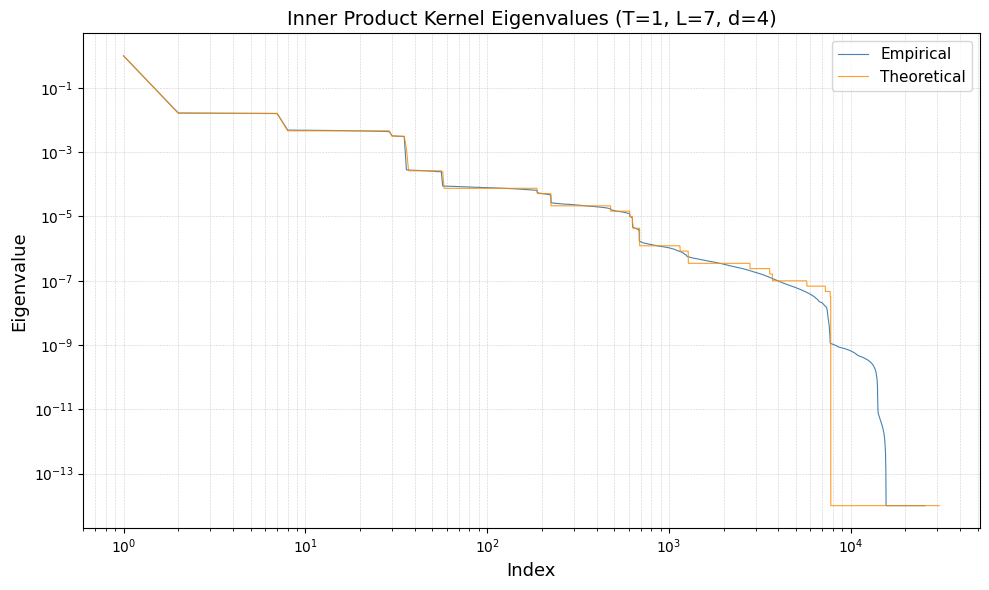

In [ ]:
def _make_title(base: str, config: dict | None, extra: str = "") -> str:
    if config is None:
        return base
    T_val, L_val = config.get("T", "?"), config.get("L", "?")
    T_str = (r"$T=\infty$"
             if (isinstance(T_val, str) and T_val.lower() in ("inf", "infinity"))
             or (isinstance(T_val, float) and math.isinf(T_val))
             else f"T={T_val}")
    suffix = f", {extra}" if extra else ""
    return f"{base} ({T_str}, L={L_val}{suffix}, d={config.get("dim")})"


def plot_eigenvalues(
    emp_eigvals,
    th_eigvals,
    outpath: str = "eigenvalues.png",
    config: dict | None = None,
    pp = None,
):
    emp = np.sort(ensure_numpy(emp_eigvals).ravel())[::-1]/n
    th  = np.sort(ensure_numpy(th_eigvals).ravel())[::-1]*pp

    title = _make_title("Inner Product Kernel Eigenvalues", config)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(np.arange(1, len(emp)+1), np.clip(emp, 1e-14, None),
            color="steelblue",  lw=0.8, label="Empirical")
    ax.plot(np.arange(1, len(th) +1), np.clip(th,  1e-14, None),
            color="darkorange", lw=0.8, label="Theoretical", alpha=0.85)
    # ax.hlines(y=9.110749270210151e-05, xmin=1, xmax=2000, colors='red')
    # ax.hlines(y=6.9724761326085576e-06, xmin=1, xmax=2000, colors='blue')
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Index", fontsize=13)
    ax.set_ylabel("Eigenvalue", fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.grid(True, which="both", linestyle="--", linewidth=0.4, alpha=0.6)
    ax.legend(fontsize=11)
    fig.tight_layout()
    # fig.savefig(outpath, dpi=150)
    plt.show()
    # plt.close(fig)
    # print(f"Figure saved \u2192 {outpath}")


plot_eigenvalues(
    out["emp_eigvals"], out["th_eigvals"],
    outpath="plots/eigenvalues.png", config=config,
    pp = 1
)

In [ ]:
folder_path = '/content/drive/My Drive/picl/results/kernels/eigenstructure/'
file_path = os.path.join(folder_path, 'innerproductkernel_T1_L7_d4.pkl')
savedict = {
    "config": config,
    "results": {
        "emp_eigs": out["emp_eigvals"],
        "th_eigs": out["th_eigvals"],
    }
}
os.makedirs(folder_path, exist_ok=True)
with open(file_path, 'wb') as f:
    pickle.dump(savedict, f)

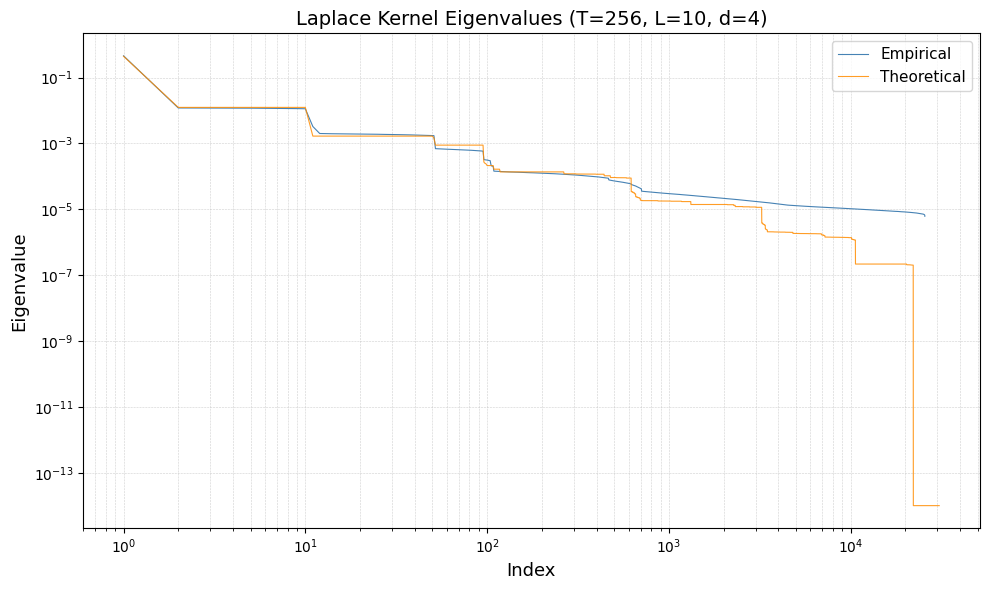

In [ ]:
def _make_title(base: str, config: dict | None, extra: str = "") -> str:
    if config is None:
        return base
    T_val, L_val = config.get("T", "?"), config.get("L", "?")
    T_str = (r"$T=\infty$"
             if (isinstance(T_val, str) and T_val.lower() in ("inf", "infinity"))
             or (isinstance(T_val, float) and math.isinf(T_val))
             else f"T={T_val}")
    suffix = f", {extra}" if extra else ""
    return f"{base} ({T_str}, L={L_val}{suffix}, d={config.get("dim")})"


def plot_eigenvalues(
    emp_eigvals,
    th_eigvals,
    outpath: str = "eigenvalues.png",
    config: dict | None = None,
    pp = None,
):
    emp = np.sort(ensure_numpy(emp_eigvals).ravel())[::-1]/n
    th  = np.sort(ensure_numpy(th_eigvals).ravel())[::-1]*pp

    title = _make_title("Laplace Kernel Eigenvalues", config)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(np.arange(1, len(emp)+1), np.clip(emp, 1e-14, None),
            color="steelblue",  lw=0.8, label="Empirical")
    ax.plot(np.arange(1, len(th) +1), np.clip(th,  1e-14, None),
            color="darkorange", lw=0.8, label="Theoretical", alpha=0.85)
    # ax.hlines(y=9.110749270210151e-05, xmin=1, xmax=2000, colors='red')
    # ax.hlines(y=6.9724761326085576e-06, xmin=1, xmax=2000, colors='blue')
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Index", fontsize=13)
    ax.set_ylabel("Eigenvalue", fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.grid(True, which="both", linestyle="--", linewidth=0.4, alpha=0.6)
    ax.legend(fontsize=11)
    fig.tight_layout()
    # fig.savefig(outpath, dpi=150)
    plt.show()
    # plt.close(fig)
    # print(f"Figure saved \u2192 {outpath}")


plot_eigenvalues(
    out["emp_eigvals"], out["th_eigvals"],
    outpath="plots/eigenvalues.png", config=config,
    pp = 1
)

In [ ]:
folder_path = '/content/drive/My Drive/picl/results/kernels/eigenstructure/'
file_path = os.path.join(folder_path, 'laplacekernel_T256_L10_d4.pkl')
savedict = {
    "config": config,
    "results": {
        "emp_eigs": out["emp_eigvals"],
        "th_eigs": out["th_eigvals"],
    }
}
os.makedirs(folder_path, exist_ok=True)
with open(file_path, 'wb') as f:
    pickle.dump(savedict, f)

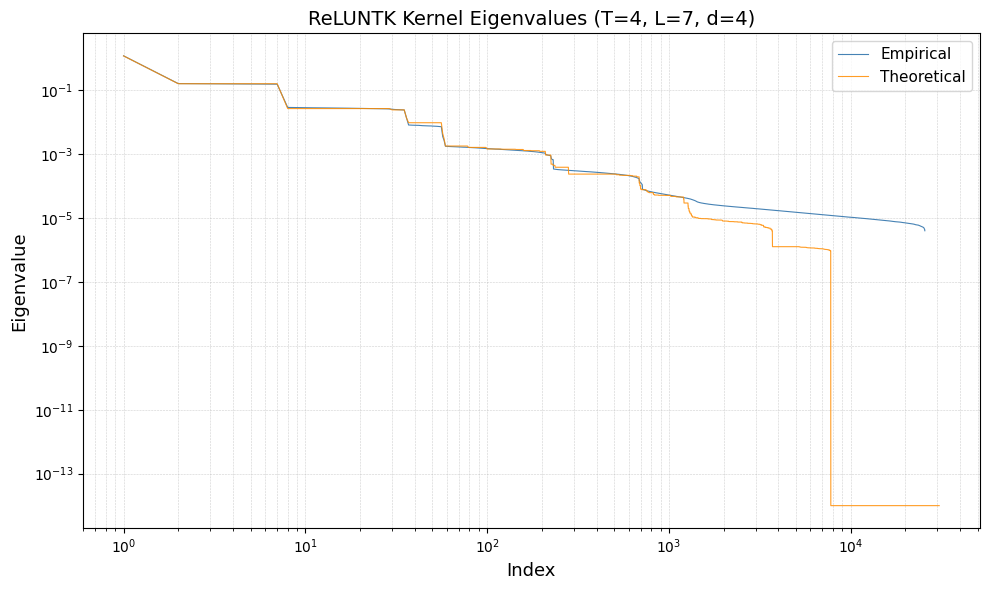

In [ ]:
def _make_title(base: str, config: dict | None, extra: str = "") -> str:
    if config is None:
        return base
    T_val, L_val = config.get("T", "?"), config.get("L", "?")
    T_str = (r"$T=\infty$"
             if (isinstance(T_val, str) and T_val.lower() in ("inf", "infinity"))
             or (isinstance(T_val, float) and math.isinf(T_val))
             else f"T={T_val}")
    suffix = f", {extra}" if extra else ""
    return f"{base} ({T_str}, L={L_val}{suffix}, d={config.get("dim")})"


def plot_eigenvalues(
    emp_eigvals,
    th_eigvals,
    outpath: str = "eigenvalues.png",
    config: dict | None = None,
    pp = None,
):
    emp = np.sort(ensure_numpy(emp_eigvals).ravel())[::-1]/n
    th  = np.sort(ensure_numpy(th_eigvals).ravel())[::-1]*pp

    title = _make_title("ReLUNTK Kernel Eigenvalues", config)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(np.arange(1, len(emp)+1), np.clip(emp, 1e-14, None),
            color="steelblue",  lw=0.8, label="Empirical")
    ax.plot(np.arange(1, len(th) +1), np.clip(th,  1e-14, None),
            color="darkorange", lw=0.8, label="Theoretical", alpha=0.85)
    # ax.hlines(y=9.110749270210151e-05, xmin=1, xmax=2000, colors='red')
    # ax.hlines(y=6.9724761326085576e-06, xmin=1, xmax=2000, colors='blue')
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Index", fontsize=13)
    ax.set_ylabel("Eigenvalue", fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.grid(True, which="both", linestyle="--", linewidth=0.4, alpha=0.6)
    ax.legend(fontsize=11)
    fig.tight_layout()
    # fig.savefig(outpath, dpi=150)
    plt.show()
    # plt.close(fig)
    # print(f"Figure saved \u2192 {outpath}")


plot_eigenvalues(
    out["emp_eigvals"], out["th_eigvals"],
    outpath="plots/eigenvalues.png", config=config,
    pp = 1
)

0.75077003 0.7801437377929688


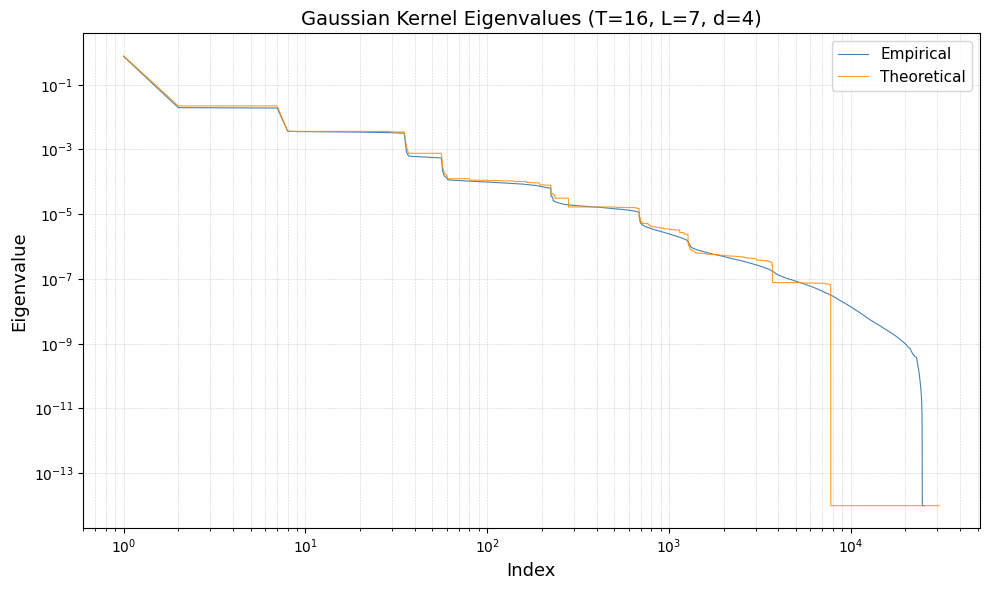

In [ ]:
def _make_title(base: str, config: dict | None, extra: str = "") -> str:
    if config is None:
        return base
    T_val, L_val = config.get("T", "?"), config.get("L", "?")
    T_str = (r"$T=\infty$"
             if (isinstance(T_val, str) and T_val.lower() in ("inf", "infinity"))
             or (isinstance(T_val, float) and math.isinf(T_val))
             else f"T={T_val}")
    suffix = f", {extra}" if extra else ""
    return f"{base} ({T_str}, L={L_val}{suffix}, d={config.get("dim")})"


def plot_eigenvalues(
    emp_eigvals,
    th_eigvals,
    outpath: str = "eigenvalues.png",
    config: dict | None = None,
    pp = None,
):
    emp = np.sort(ensure_numpy(emp_eigvals).ravel())[::-1]/n
    th  = np.sort(ensure_numpy(th_eigvals).ravel())[::-1]*pp
    print(emp[0], th[0])

    title = _make_title("Gaussian Kernel Eigenvalues", config)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(np.arange(1, len(emp)+1), np.clip(emp, 1e-14, None),
            color="steelblue",  lw=0.8, label="Empirical")
    ax.plot(np.arange(1, len(th) +1), np.clip(th,  1e-14, None),
            color="darkorange", lw=0.8, label="Theoretical", alpha=0.85)
    # ax.hlines(y=9.110749270210151e-05, xmin=1, xmax=2000, colors='red')
    # ax.hlines(y=6.9724761326085576e-06, xmin=1, xmax=2000, colors='blue')
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Index", fontsize=13)
    ax.set_ylabel("Eigenvalue", fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.grid(True, which="both", linestyle="--", linewidth=0.4, alpha=0.6)
    ax.legend(fontsize=11)
    fig.tight_layout()
    # fig.savefig(outpath, dpi=150)
    plt.show()
    # plt.close(fig)
    # print(f"Figure saved \u2192 {outpath}")


plot_eigenvalues(
    out["emp_eigvals"], out["th_eigvals"],
    outpath="plots/eigenvalues.png", config=config,
    pp = out["pp"]
)

0.7452623 0.7750227451324463


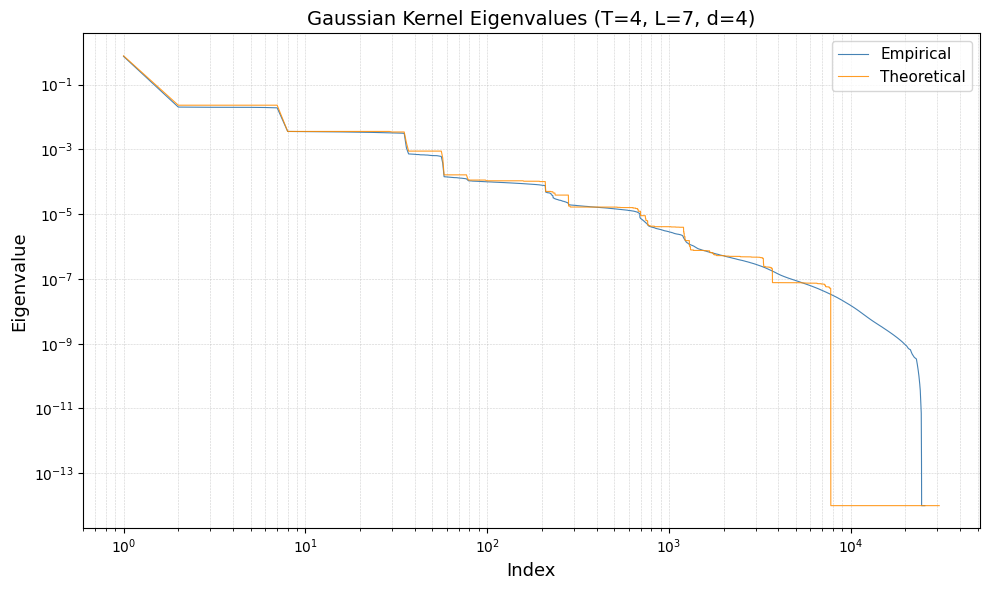

In [ ]:
def _make_title(base: str, config: dict | None, extra: str = "") -> str:
    if config is None:
        return base
    T_val, L_val = config.get("T", "?"), config.get("L", "?")
    T_str = (r"$T=\infty$"
             if (isinstance(T_val, str) and T_val.lower() in ("inf", "infinity"))
             or (isinstance(T_val, float) and math.isinf(T_val))
             else f"T={T_val}")
    suffix = f", {extra}" if extra else ""
    return f"{base} ({T_str}, L={L_val}{suffix}, d={config.get("dim")})"


def plot_eigenvalues(
    emp_eigvals,
    th_eigvals,
    outpath: str = "eigenvalues.png",
    config: dict | None = None,
    pp = None,
):
    emp = np.sort(ensure_numpy(emp_eigvals).ravel())[::-1]/n
    th  = np.sort(ensure_numpy(th_eigvals).ravel())[::-1]*pp
    print(emp[0], th[0])

    title = _make_title("Gaussian Kernel Eigenvalues", config)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(np.arange(1, len(emp)+1), np.clip(emp, 1e-14, None),
            color="steelblue",  lw=0.8, label="Empirical")
    ax.plot(np.arange(1, len(th) +1), np.clip(th,  1e-14, None),
            color="darkorange", lw=0.8, label="Theoretical", alpha=0.85)
    # ax.hlines(y=9.110749270210151e-05, xmin=1, xmax=2000, colors='red')
    # ax.hlines(y=6.9724761326085576e-06, xmin=1, xmax=2000, colors='blue')
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Index", fontsize=13)
    ax.set_ylabel("Eigenvalue", fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.grid(True, which="both", linestyle="--", linewidth=0.4, alpha=0.6)
    ax.legend(fontsize=11)
    fig.tight_layout()
    # fig.savefig(outpath, dpi=150)
    plt.show()
    # plt.close(fig)
    # print(f"Figure saved \u2192 {outpath}")


plot_eigenvalues(
    out["emp_eigvals"], out["th_eigvals"],
    outpath="plots/eigenvalues.png", config=config,
    pp = out["pp"]
)

0.7499563 0.7800265550613403


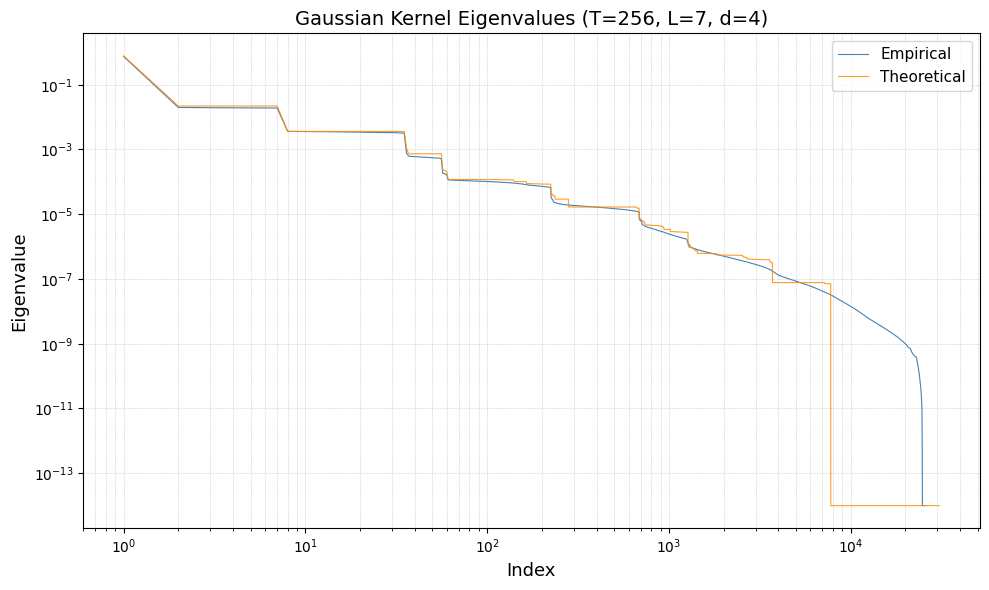

In [ ]:
def _make_title(base: str, config: dict | None, extra: str = "") -> str:
    if config is None:
        return base
    T_val, L_val = config.get("T", "?"), config.get("L", "?")
    T_str = (r"$T=\infty$"
             if (isinstance(T_val, str) and T_val.lower() in ("inf", "infinity"))
             or (isinstance(T_val, float) and math.isinf(T_val))
             else f"T={T_val}")
    suffix = f", {extra}" if extra else ""
    return f"{base} ({T_str}, L={L_val}{suffix}, d={config.get("dim")})"


def plot_eigenvalues(
    emp_eigvals,
    th_eigvals,
    outpath: str = "eigenvalues.png",
    config: dict | None = None,
    pp = None,
):
    emp = np.sort(ensure_numpy(emp_eigvals).ravel())[::-1]/n
    th  = np.sort(ensure_numpy(th_eigvals).ravel())[::-1]*pp
    print(emp[0], th[0])

    title = _make_title("Gaussian Kernel Eigenvalues", config)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(np.arange(1, len(emp)+1), np.clip(emp, 1e-14, None),
            color="steelblue",  lw=0.8, label="Empirical")
    ax.plot(np.arange(1, len(th) +1), np.clip(th,  1e-14, None),
            color="darkorange", lw=0.8, label="Theoretical", alpha=0.85)
    # ax.hlines(y=9.110749270210151e-05, xmin=1, xmax=2000, colors='red')
    # ax.hlines(y=6.9724761326085576e-06, xmin=1, xmax=2000, colors='blue')
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Index", fontsize=13)
    ax.set_ylabel("Eigenvalue", fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.grid(True, which="both", linestyle="--", linewidth=0.4, alpha=0.6)
    ax.legend(fontsize=11)
    fig.tight_layout()
    # fig.savefig(outpath, dpi=150)
    plt.show()
    # plt.close(fig)
    # print(f"Figure saved \u2192 {outpath}")


plot_eigenvalues(
    out["emp_eigvals"], out["th_eigvals"],
    outpath="plots/eigenvalues.png", config=config,
    pp = out["pp"]
)

0.7580458 0.7879598736763


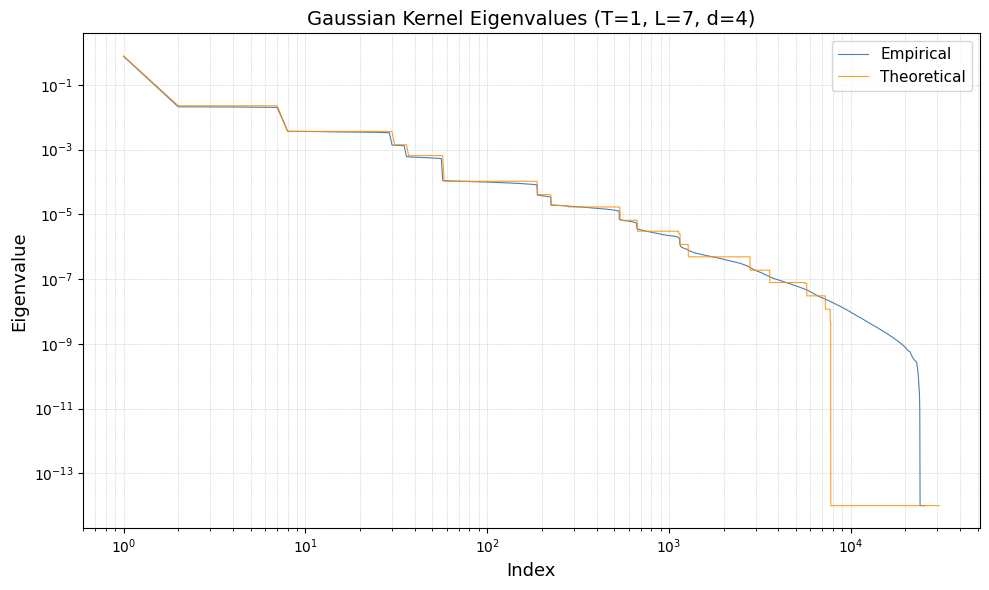

In [ ]:
def _make_title(base: str, config: dict | None, extra: str = "") -> str:
    if config is None:
        return base
    T_val, L_val = config.get("T", "?"), config.get("L", "?")
    T_str = (r"$T=\infty$"
             if (isinstance(T_val, str) and T_val.lower() in ("inf", "infinity"))
             or (isinstance(T_val, float) and math.isinf(T_val))
             else f"T={T_val}")
    suffix = f", {extra}" if extra else ""
    return f"{base} ({T_str}, L={L_val}{suffix}, d={config.get("dim")})"


def plot_eigenvalues(
    emp_eigvals,
    th_eigvals,
    outpath: str = "eigenvalues.png",
    config: dict | None = None,
    pp = None,
):
    emp = np.sort(ensure_numpy(emp_eigvals).ravel())[::-1]/n
    th  = np.sort(ensure_numpy(th_eigvals).ravel())[::-1]*pp
    print(emp[0], th[0])

    title = _make_title("Gaussian Kernel Eigenvalues", config)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(np.arange(1, len(emp)+1), np.clip(emp, 1e-14, None),
            color="steelblue",  lw=0.8, label="Empirical")
    ax.plot(np.arange(1, len(th) +1), np.clip(th,  1e-14, None),
            color="darkorange", lw=0.8, label="Theoretical", alpha=0.85)
    # ax.hlines(y=9.110749270210151e-05, xmin=1, xmax=2000, colors='red')
    # ax.hlines(y=6.9724761326085576e-06, xmin=1, xmax=2000, colors='blue')
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Index", fontsize=13)
    ax.set_ylabel("Eigenvalue", fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.grid(True, which="both", linestyle="--", linewidth=0.4, alpha=0.6)
    ax.legend(fontsize=11)
    fig.tight_layout()
    # fig.savefig(outpath, dpi=150)
    plt.show()
    # plt.close(fig)
    # print(f"Figure saved \u2192 {outpath}")


plot_eigenvalues(
    out["emp_eigvals"], out["th_eigvals"],
    outpath="plots/eigenvalues.png", config=config,
    pp = out["pp"]
)

In [ ]:
folder_path = '/content/drive/My Drive/picl/results/kernels/eigenstructure/'
file_path = os.path.join(folder_path, 'laplacekernel_T16_L7_d4.pkl')
savedict = {
    "config": config,
    "results": {
        "emp_eigs": out["emp_eigvals"],
        "th_eigs": out["th_eigvals"],
    }
}
os.makedirs(folder_path, exist_ok=True)
with open(file_path, 'wb') as f:
    pickle.dump(savedict, f)

## Eigenvector coefficients: empirical vs theoretical (HEA)

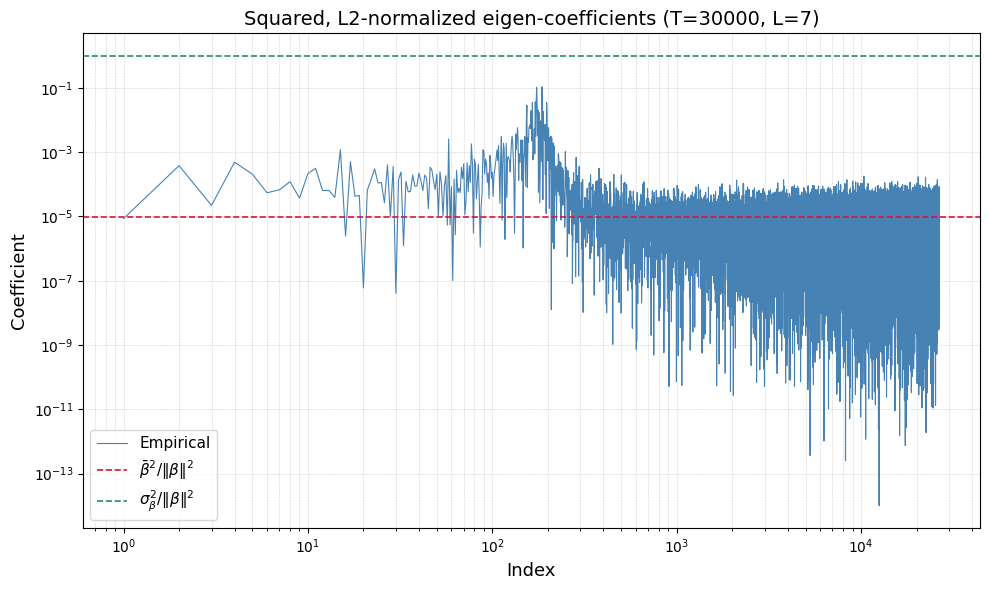

In [ ]:
hlines = None
if "gaussian_beta_weight_fractions" in out:
    fracs = out["gaussian_beta_weight_fractions"]
    mf = float(ensure_numpy(fracs["mean_fraction"]).ravel()[0])
    sf = float(ensure_numpy(fracs["std_fraction"]).ravel()[0])
    hlines = {
        r"$\bar\beta^2 / \|\beta\|^2$": (mf**2, "crimson"),
        r"$\sigma^2_\beta / \|\beta\|^2$": (sf**2, "seagreen"),
    }

emp = np.clip(ensure_numpy(out["emp_eigcoeffs_sq_normalized"]).ravel(), 1e-14, None)
# th  = np.clip(ensure_numpy(out["th_eigcoeffs_sq_normalized"]).ravel(),  1e-14, None)
title = _make_title("Squared, L2-normalized eigen-coefficients", config)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(np.arange(1, len(emp)+1), emp, color="steelblue",  lw=0.8, label="Empirical")
# ax.plot(np.arange(1, len(th) +1), th,  color="darkorange", lw=0.8, label="Theoretical (HEA)", alpha=0.85)
if hlines:
    for hline_label, (val, hcolor) in hlines.items():
        val = float(np.clip(val, 1e-14, None))
        ax.axhline(val, color=hcolor, linewidth=1.2, linestyle="--", label=hline_label)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Index", fontsize=13)
ax.set_ylabel("Coefficient", fontsize=13)
ax.set_title(title, fontsize=14)
ax.grid(True, which="both", linestyle="--", linewidth=0.4, alpha=0.6)
ax.legend(fontsize=11)
fig.tight_layout()
# fig.savefig("plots/eigcoeffs_combined.png", dpi=150)
plt.show()
# plt.close(fig)
# print("Figure saved \u2192 plots/eigcoeffs_combined.png")